In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("customer_churn_preprocessed.csv")

log_model = joblib.load("logistic_regression_model.pkl")
dt_model = joblib.load("decision_tree_model.pkl")
rf_model = joblib.load("random_forest_model.pkl")

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Dataset Loaded:", df.shape)
print("All Models Loaded Successfully!")

Dataset Loaded: (7043, 31)
All Models Loaded Successfully!


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Test Data:", X_test.shape)

Test Data: (1409, 30)


In [4]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

comparison = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8041,0.6541,0.5561,0.6012,0.8428
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267
2,Random Forest,0.8062,0.6700,0.5321,0.5931,0.8435


In [5]:
best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", comparison_df["F1 Score"].max())

Best Model: Logistic Regression
Best F1 Score: 0.6011560693641619


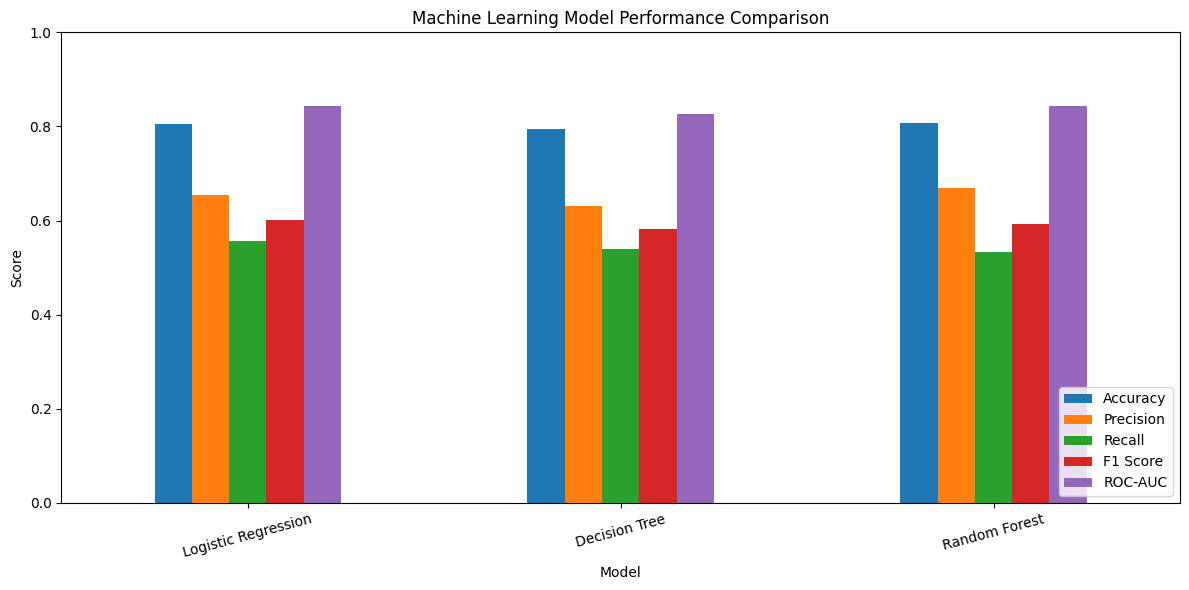

In [6]:
comparison_plot = comparison_df.set_index("Model")

comparison_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
if best_model_name in ["Decision Tree", "Random Forest"]:

    importance = best_model.feature_importances_

else:

    importance = np.abs(best_model.coef_[0])

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
25,Contract_Two year,1.328605
10,InternetService_Fiber optic,0.744096
24,Contract_One year,0.685712
7,PhoneService_Yes,0.440448
13,OnlineSecurity_Yes,0.431675
28,PaymentMethod_Electronic check,0.390784
19,TechSupport_Yes,0.384448
26,PaperlessBilling_Yes,0.373610
9,MultipleLines_Yes,0.274699
6,Dependents_Yes,0.221900


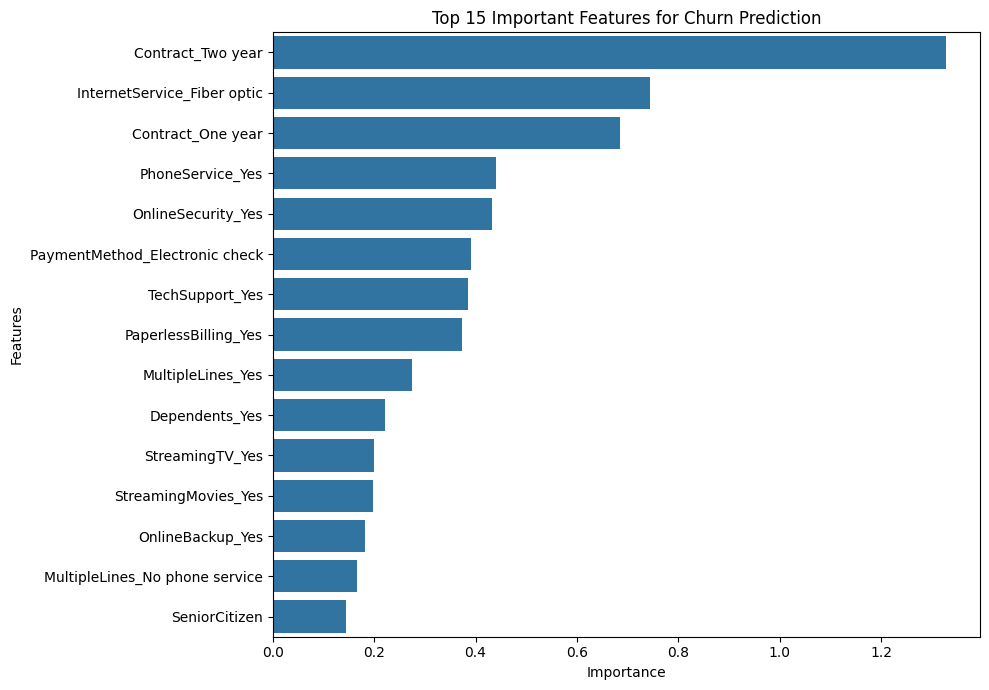

In [8]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Churn Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [9]:
def predict_customer_churn(customer_data):

    customer_df = pd.DataFrame(
        [customer_data],
        columns=X.columns
    )

    prediction = best_model.predict(customer_df)[0]

    probability = best_model.predict_proba(customer_df)[0][1]

    if probability >= 0.70:
        risk = "High Risk"
    elif probability >= 0.40:
        risk = "Medium Risk"
    else:
        risk = "Low Risk"

    print("Customer Churn Prediction")
    print("-------------------------")
    print("Prediction:", "Churn" if prediction == 1 else "No Churn")
    print("Churn Probability:", round(probability * 100, 2), "%")
    print("Risk Level:", risk)

    return prediction, probability, risk

In [10]:
sample_customer = X_test.iloc[0].to_dict()

prediction, probability, risk = predict_customer_churn(
    sample_customer
)

Customer Churn Prediction
-------------------------
Prediction: No Churn
Churn Probability: 4.67 %
Risk Level: Low Risk


In [11]:
def retention_recommendations(risk):

    print("Customer Retention Recommendations")
    print("----------------------------------")

    if risk == "High Risk":

        print("1. Contact the customer immediately.")
        print("2. Provide personalized discounts or offers.")
        print("3. Understand the customer's service complaints.")
        print("4. Offer suitable subscription plans.")

    elif risk == "Medium Risk":

        print("1. Send personalized engagement messages.")
        print("2. Provide loyalty benefits.")
        print("3. Collect customer feedback.")
        print("4. Monitor customer satisfaction.")

    else:

        print("1. Continue providing quality service.")
        print("2. Offer loyalty rewards.")
        print("3. Maintain regular customer engagement.")
        print("4. Encourage referrals.")

retention_recommendations(risk)

Customer Retention Recommendations
----------------------------------
1. Continue providing quality service.
2. Offer loyalty rewards.
3. Maintain regular customer engagement.
4. Encourage referrals.


In [12]:
comparison_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "customer_churn_feature_importance.csv",
    index=False
)

joblib.dump(best_model, "best_churn_model.pkl")

print("Final results and best model saved successfully!")

Final results and best model saved successfully!


In [15]:
print("CUSTOMER CHURN PREDICTION & RETENTION ANALYSIS")
print("=" * 50)

print("Total Customers:", len(df))
print("Total Features:", X.shape[1])

print("\nModels Evaluated:")
for name in models:
    print("-", name)

print("\nBest Model:", best_model_name)

print("\nFinal Project Tasks:")
print("1. Data Understanding and EDA")
print("2. Data Cleaning and Preprocessing")
print("3. Machine Learning Model Training")
print("4. Model Evaluation and Comparison")
print("5. Feature Importance Analysis")
print("6. Customer Churn Risk Prediction")
print("7. Retention Recommendations")

CUSTOMER CHURN PREDICTION & RETENTION ANALYSIS
Total Customers: 7043
Total Features: 30

Models Evaluated:
- Logistic Regression
- Decision Tree
- Random Forest

Best Model: Logistic Regression

Final Project Tasks:
1. Data Understanding and EDA
2. Data Cleaning and Preprocessing
3. Machine Learning Model Training
4. Model Evaluation and Comparison
5. Feature Importance Analysis
6. Customer Churn Risk Prediction
7. Retention Recommendations
